In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np

from src.data.loader import load_parquet
from src.models.baseline import build_baseline_pipeline, split_X_y, FEATURE_COLUMNS

train_df = load_parquet("../data/processed/train_fe.parquet")
val_df   = load_parquet("../data/processed/val_fe.parquet")

X_train, y_train = split_X_y(train_df)
X_val,   y_val   = split_X_y(val_df)

print(f"X_train: {X_train.shape}, fraud rate: {y_train.mean()*100:.3f}%")
print(f"X_val:   {X_val.shape}, fraud rate: {y_val.mean()*100:.3f}%")
print(f"\nUsing {len(FEATURE_COLUMNS)} features.")

X_train: (198648, 35), fraud rate: 0.184%
X_val:   (42721, 35), fraud rate: 0.131%

Using 35 features.


In [2]:
from time import time

pipeline = build_baseline_pipeline()

t0 = time()
pipeline.fit(X_train, y_train)
train_time = time() - t0

print(f"Trained in {train_time:.1f} seconds.")

# Get fraud probabilities on validation set
val_probs = pipeline.predict_proba(X_val)[:, 1]
print(f"Prob array shape: {val_probs.shape}")
print(f"Prob range: [{val_probs.min():.4f}, {val_probs.max():.4f}]")
print(f"Mean prob: {val_probs.mean():.4f}")

Trained in 1.3 seconds.
Prob array shape: (42721,)
Prob range: [0.0000, 1.0000]
Mean prob: 0.1253


In [3]:
from src.evaluation.metrics import compute_core_metrics, precision_recall_at_k

# Core metrics at default 0.5 threshold
core = compute_core_metrics(y_val.values, val_probs, threshold=0.5)

print("=== Baseline Logistic Regression — Validation Set ===")
print(f"ROC-AUC:   {core['roc_auc']:.4f}")
print(f"PR-AUC:    {core['pr_auc']:.4f}  (random baseline: {y_val.mean():.4f})")
print(f"\nAt threshold = 0.5:")
print(f"  Precision: {core['precision']:.4f}")
print(f"  Recall:    {core['recall']:.4f}")
print(f"  F1:        {core['f1']:.4f}")
print(f"\nConfusion matrix:")
print(f"              Predicted Legit  Predicted Fraud")
print(f"  Actual Legit  {core['true_neg']:>10,}      {core['false_pos']:>10,}")
print(f"  Actual Fraud  {core['false_neg']:>10,}      {core['true_pos']:>10,}")

=== Baseline Logistic Regression — Validation Set ===
ROC-AUC:   0.9811
PR-AUC:    0.8447  (random baseline: 0.0013)

At threshold = 0.5:
  Precision: 0.0188
  Recall:    0.9286
  F1:        0.0369

Confusion matrix:
              Predicted Legit  Predicted Fraud
  Actual Legit      39,957           2,708
  Actual Fraud           4              52


In [4]:
print("=== Precision@k and Recall@k (validation set) ===")
print(f"{'k':>5s}  {'Precision@k':>12s}  {'Recall@k':>10s}  {'Fraud caught':>14s}")
for k in [50, 100, 200, 500, 1000]:
    r = precision_recall_at_k(y_val.values, val_probs, k=k)
    print(f"{k:>5d}  {r['precision_at_k']:>12.3f}  {r['recall_at_k']:>10.3f}"
          f"  {r['fraud_caught']:>5d}/{r['fraud_total']:<5d}")

=== Precision@k and Recall@k (validation set) ===
    k   Precision@k    Recall@k    Fraud caught
   50         0.860       0.768     43/56   
  100         0.490       0.875     49/56   
  200         0.255       0.911     51/56   
  500         0.104       0.929     52/56   
 1000         0.052       0.929     52/56   


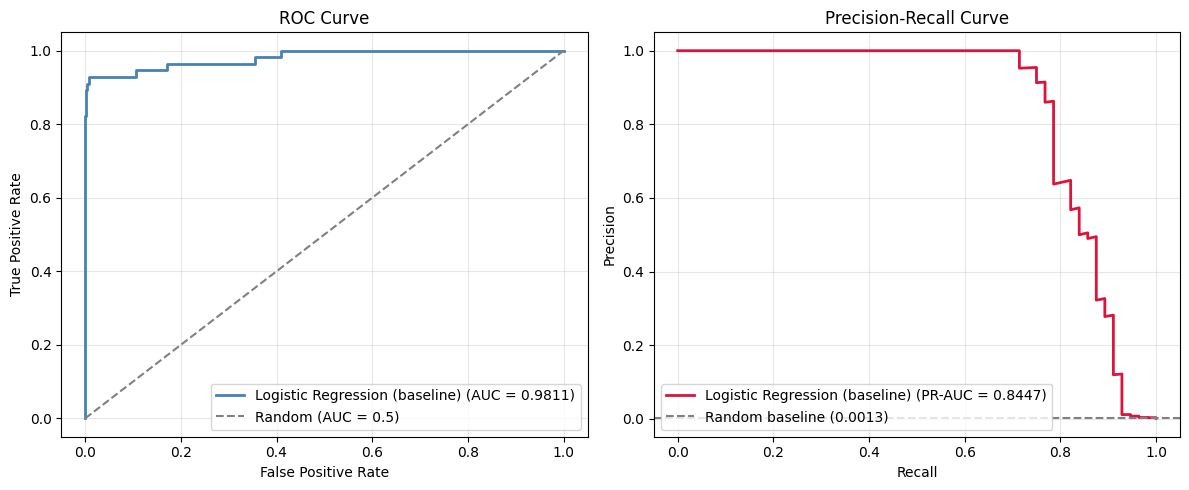

In [5]:
from src.evaluation.plots import plot_roc_and_pr

plot_roc_and_pr(y_val.values, val_probs, model_name="Logistic Regression (baseline)")

In [6]:
from src.models.random_forest import build_random_forest_pipeline
from time import time

rf_pipeline = build_random_forest_pipeline()

t0 = time()
rf_pipeline.fit(X_train, y_train)
rf_train_time = time() - t0

rf_val_probs = rf_pipeline.predict_proba(X_val)[:, 1]

print(f"Random Forest trained in {rf_train_time:.1f} seconds.")
print(f"Prob range: [{rf_val_probs.min():.4f}, {rf_val_probs.max():.4f}]")
print(f"Mean prob:  {rf_val_probs.mean():.4f}")

Random Forest trained in 26.0 seconds.
Prob range: [0.0000, 0.9750]
Mean prob:  0.0013


In [7]:
from src.evaluation.metrics import compute_core_metrics, precision_recall_at_k

lr_metrics = compute_core_metrics(y_val.values, val_probs, threshold=0.5)
rf_metrics = compute_core_metrics(y_val.values, rf_val_probs, threshold=0.5)

print("=== Baseline vs Random Forest — Validation ===")
print(f"{'Metric':<15s} {'LogReg':>12s} {'RandomForest':>14s} {'Delta':>10s}")
for key in ["roc_auc", "pr_auc", "precision", "recall", "f1"]:
    delta = rf_metrics[key] - lr_metrics[key]
    sign = "+" if delta >= 0 else ""
    print(f"{key:<15s} {lr_metrics[key]:>12.4f} {rf_metrics[key]:>14.4f} {sign}{delta:>9.4f}")

print(f"\nPrecision@k comparison:")
print(f"{'k':>5s}  {'LR p@k':>8s}  {'RF p@k':>8s}  {'LR r@k':>8s}  {'RF r@k':>8s}")
for k in [50, 100, 200, 500]:
    lr_k = precision_recall_at_k(y_val.values, val_probs, k)
    rf_k = precision_recall_at_k(y_val.values, rf_val_probs, k)
    print(f"{k:>5d}  {lr_k['precision_at_k']:>8.3f}  {rf_k['precision_at_k']:>8.3f}"
          f"  {lr_k['recall_at_k']:>8.3f}  {rf_k['recall_at_k']:>8.3f}")

=== Baseline vs Random Forest — Validation ===
Metric                LogReg   RandomForest      Delta
roc_auc               0.9811         0.9799   -0.0012
pr_auc                0.8447         0.8707 +   0.0259
precision             0.0188         1.0000 +   0.9812
recall                0.9286         0.6964   -0.2321
f1                    0.0369         0.8211 +   0.7841

Precision@k comparison:
    k    LR p@k    RF p@k    LR r@k    RF r@k
   50     0.860     0.920     0.768     0.821
  100     0.490     0.500     0.875     0.893
  200     0.255     0.250     0.911     0.893
  500     0.104     0.104     0.929     0.929


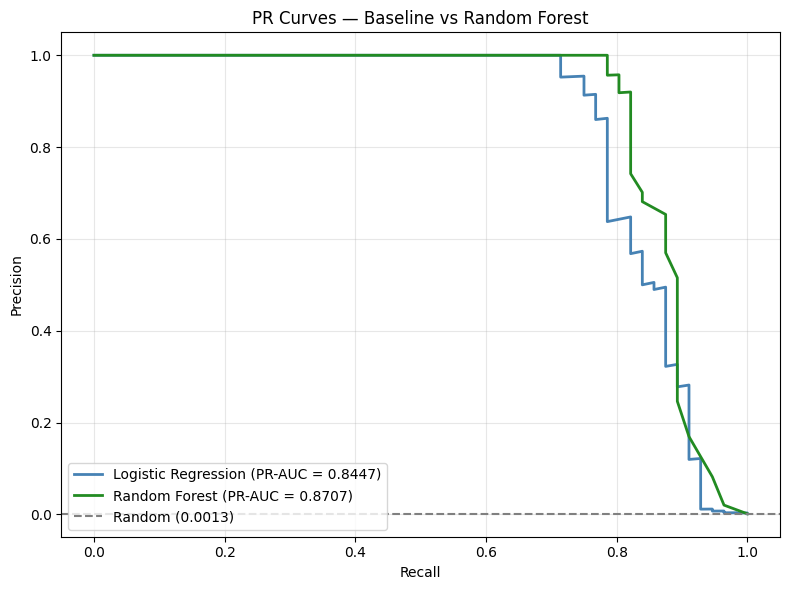

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(8, 6))

for name, probs, color in [
    ("Logistic Regression", val_probs, "steelblue"),
    ("Random Forest",       rf_val_probs, "forestgreen"),
]:
    p, r, _ = precision_recall_curve(y_val.values, probs)
    auc = average_precision_score(y_val.values, probs)
    ax.plot(r, p, label=f"{name} (PR-AUC = {auc:.4f})", linewidth=2, color=color)

ax.axhline(y_val.mean(), linestyle="--", color="gray", label=f"Random ({y_val.mean():.4f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("PR Curves — Baseline vs Random Forest")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
from src.models.xgboost_model import build_xgboost_pipeline, compute_scale_pos_weight
from time import time

spw = compute_scale_pos_weight(y_train)
print(f"scale_pos_weight = {spw:.1f}  (negative/positive ratio in training)")

xgb_pipeline = build_xgboost_pipeline(scale_pos_weight=spw)

t0 = time()
xgb_pipeline.fit(X_train, y_train)
xgb_train_time = time() - t0

xgb_val_probs = xgb_pipeline.predict_proba(X_val)[:, 1]

print(f"\nXGBoost trained in {xgb_train_time:.1f} seconds.")
print(f"Prob range: [{xgb_val_probs.min():.4f}, {xgb_val_probs.max():.4f}]")
print(f"Mean prob:  {xgb_val_probs.mean():.4f}")

scale_pos_weight = 541.8  (negative/positive ratio in training)

XGBoost trained in 2.6 seconds.
Prob range: [0.0000, 1.0000]
Mean prob:  0.0012


In [10]:
from src.evaluation.metrics import compute_core_metrics, precision_recall_at_k

lr_m  = compute_core_metrics(y_val.values, val_probs, threshold=0.5)
rf_m  = compute_core_metrics(y_val.values, rf_val_probs, threshold=0.5)
xgb_m = compute_core_metrics(y_val.values, xgb_val_probs, threshold=0.5)

print("=== Three-way model comparison on validation ===")
print(f"{'Metric':<12s} {'LogReg':>10s} {'RForest':>10s} {'XGBoost':>10s}")
for key in ["roc_auc", "pr_auc", "precision", "recall", "f1"]:
    print(f"{key:<12s} {lr_m[key]:>10.4f} {rf_m[key]:>10.4f} {xgb_m[key]:>10.4f}")

print(f"\n{'k':>5s} {'LR p@k':>8s} {'RF p@k':>8s} {'XGB p@k':>8s}"
      f" {'LR r@k':>8s} {'RF r@k':>8s} {'XGB r@k':>8s}")
for k in [50, 100, 200, 500]:
    lr_k  = precision_recall_at_k(y_val.values, val_probs, k)
    rf_k  = precision_recall_at_k(y_val.values, rf_val_probs, k)
    xgb_k = precision_recall_at_k(y_val.values, xgb_val_probs, k)
    print(f"{k:>5d} {lr_k['precision_at_k']:>8.3f} {rf_k['precision_at_k']:>8.3f}"
          f" {xgb_k['precision_at_k']:>8.3f}"
          f" {lr_k['recall_at_k']:>8.3f} {rf_k['recall_at_k']:>8.3f}"
          f" {xgb_k['recall_at_k']:>8.3f}")

=== Three-way model comparison on validation ===
Metric           LogReg    RForest    XGBoost
roc_auc          0.9811     0.9799     0.9880
pr_auc           0.8447     0.8707     0.8477
precision        0.0188     1.0000     0.9167
recall           0.9286     0.6964     0.7857
f1               0.0369     0.8211     0.8462

    k   LR p@k   RF p@k  XGB p@k   LR r@k   RF r@k  XGB r@k
   50    0.860    0.920    0.900    0.768    0.821    0.804
  100    0.490    0.500    0.470    0.875    0.893    0.839
  200    0.255    0.250    0.245    0.911    0.893    0.875
  500    0.104    0.104    0.104    0.929    0.929    0.929


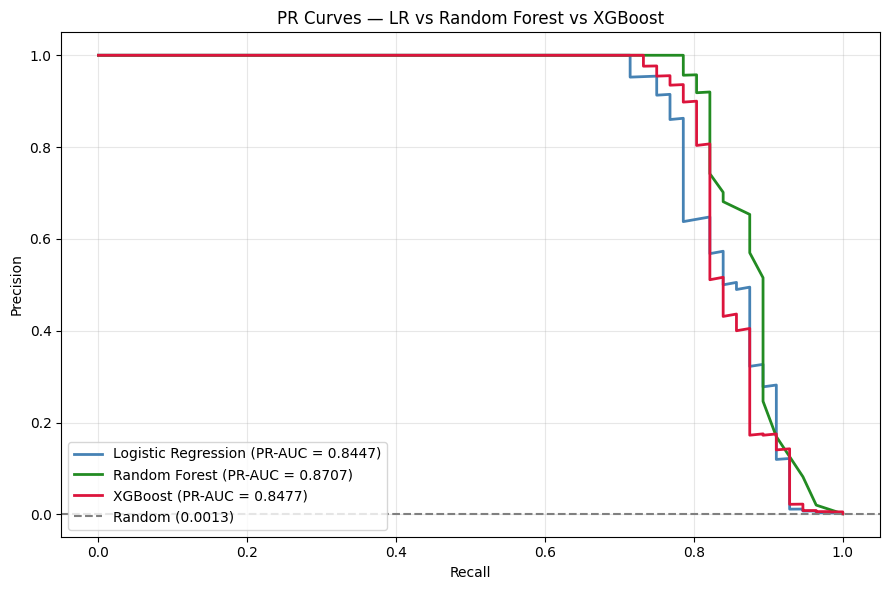

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(9, 6))

for name, probs, color in [
    ("Logistic Regression", val_probs,     "steelblue"),
    ("Random Forest",       rf_val_probs,  "forestgreen"),
    ("XGBoost",             xgb_val_probs, "crimson"),
]:
    p, r, _ = precision_recall_curve(y_val.values, probs)
    auc = average_precision_score(y_val.values, probs)
    ax.plot(r, p, label=f"{name} (PR-AUC = {auc:.4f})", linewidth=2, color=color)

ax.axhline(y_val.mean(), linestyle="--", color="gray", label=f"Random ({y_val.mean():.4f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("PR Curves — LR vs Random Forest vs XGBoost")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)
joblib.dump(xgb_pipeline, "../models/xgboost_pipeline.joblib")
print("XGBoost pipeline saved to models/xgboost_pipeline.joblib")

XGBoost pipeline saved to models/xgboost_pipeline.joblib


In [13]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)
joblib.dump(rf_pipeline, "../models/rf_pipeline.joblib")
print("Random Forest pipeline saved to models/rf_pipeline.joblib")

Random Forest pipeline saved to models/rf_pipeline.joblib


In [16]:
from src.evaluation.threshold import sweep_thresholds, pick_threshold_by_cost
import numpy as np

# Finer sweep that goes closer to zero so the optimizer doesn't hit a boundary
sweep = sweep_thresholds(
    y_val.values,
    rf_val_probs,
    thresholds=np.linspace(0.001, 0.99, 200),
)

# Try three business scenarios — show the trade-off, don't commit to one.
scenarios = [
    ("Conservative (fraud cheap, reviews expensive)", 500,  5),
    ("Balanced (realistic bank defaults)",            2000, 3),
    ("Aggressive (fraud expensive, reviews cheap)",   5000, 2),
]

print(f"{'Scenario':<48s} {'t*':>6s} {'Prec':>6s} {'Rec':>6s} {'TP':>4s} {'FP':>5s} {'FN':>4s} {'Cost (€)':>10s}")
for name, c_fn, c_fp in scenarios:
    r = pick_threshold_by_cost(sweep, cost_fn=c_fn, cost_fp=c_fp)["best"]

Scenario                                             t*   Prec    Rec   TP    FP   FN   Cost (€)


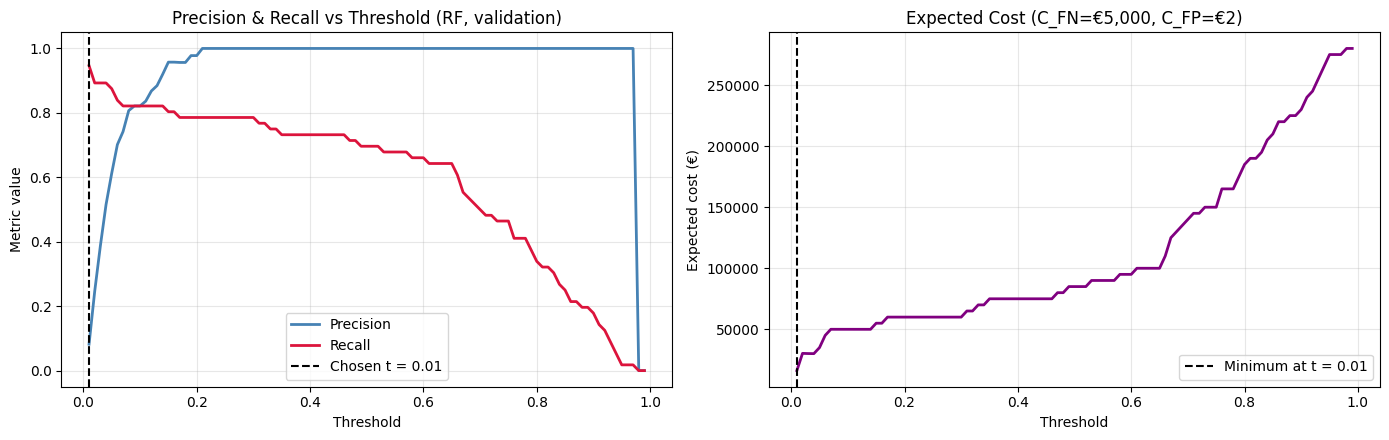

In [15]:
import matplotlib.pyplot as plt

sweep_c = result["sweep_with_cost"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: precision & recall vs threshold
axes[0].plot(sweep_c["threshold"], sweep_c["precision"], label="Precision", color="steelblue", linewidth=2)
axes[0].plot(sweep_c["threshold"], sweep_c["recall"],    label="Recall",    color="crimson",   linewidth=2)
axes[0].axvline(best["threshold"], color="black", linestyle="--", label=f"Chosen t = {best['threshold']:.2f}")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Metric value")
axes[0].set_title("Precision & Recall vs Threshold (RF, validation)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: expected cost vs threshold
axes[1].plot(sweep_c["threshold"], sweep_c["expected_cost"], color="purple", linewidth=2)
axes[1].axvline(best["threshold"], color="black", linestyle="--", label=f"Minimum at t = {best['threshold']:.2f}")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Expected cost (€)")
axes[1].set_title(f"Expected Cost (C_FN=€{COST_FN:,.0f}, C_FP=€{COST_FP:.0f})")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
for name, c_fn, c_fp in scenarios:
    r = pick_threshold_by_cost(sweep, cost_fn=c_fn, cost_fp=c_fp)["best"]
    print(f"{name:<48s} "
          f"{r['threshold']:>6.3f} {r['precision']:>6.3f} {r['recall']:>6.3f} "
          f"{int(r['tp']):>4d} {int(r['fp']):>5d} {int(r['fn']):>4d} {r['expected_cost']:>10,.0f}")

Conservative (fraud cheap, reviews expensive)     0.036  0.515  0.893   50    47    6      3,235
Balanced (realistic bank defaults)                0.006  0.082  0.946   53   593    3      7,779
Aggressive (fraud expensive, reviews cheap)       0.001  0.020  0.964   54  2614    2     15,228


In [20]:
# Lock in the operating point: realistic bank defaults
PRODUCTION_C_FN = 500.0  # Average loss per missed fraud (€)
PRODUCTION_C_FP = 5.0    # Reviewer cost per false alert (€)

result = pick_threshold_by_cost(sweep, cost_fn=PRODUCTION_C_FN, cost_fp=PRODUCTION_C_FP)
PRODUCTION_THRESHOLD = float(result["best"]["threshold"])

print(f"Production threshold: {PRODUCTION_THRESHOLD:.4f}")
print(f"At this threshold on validation:")
print(f"  Precision: {result['best']['precision']:.3f}")
print(f"  Recall:    {result['best']['recall']:.3f}")
print(f"  TP: {int(result['best']['tp'])}, FP: {int(result['best']['fp'])}, "
      f"FN: {int(result['best']['fn'])}, TN: {int(result['best']['tn']):,}")

Production threshold: 0.0358
At this threshold on validation:
  Precision: 0.515
  Recall:    0.893
  TP: 50, FP: 47, FN: 6, TN: 42,618


In [21]:
# Find the threshold where precision first crosses 0.80 on validation
sweep_sorted = sweep.sort_values("threshold")
high_candidates = sweep_sorted[sweep_sorted["precision"] >= 0.80]
HIGH_CONFIDENCE_THRESHOLD = float(high_candidates["threshold"].min()) if len(high_candidates) else 0.5

print(f"Low cutoff (production threshold):  {PRODUCTION_THRESHOLD:.4f}")
print(f"High cutoff (precision >= 0.80):    {HIGH_CONFIDENCE_THRESHOLD:.4f}")

Low cutoff (production threshold):  0.0358
High cutoff (precision >= 0.80):    0.0755


In [22]:
from src.inference.risk_score import RiskConfig, score_transactions

config = RiskConfig(
    low_cutoff=PRODUCTION_THRESHOLD,
    high_cutoff=HIGH_CONFIDENCE_THRESHOLD,
)

scored = score_transactions(rf_val_probs, config)
scored["actual_class"] = y_val.values

print("=== Risk category distribution on validation ===")
summary = scored.groupby("risk_category").agg(
    count=("probability", "size"),
    frauds=("actual_class", "sum"),
    precision=("actual_class", "mean"),
).reindex(["Low", "Medium", "High"])
summary["pct_of_transactions"] = (summary["count"] / len(scored) * 100).round(2)
summary["precision"] = (summary["precision"] * 100).round(1)
print(summary)

print("\n=== Example scored transactions (top 5 by risk) ===")
print(scored.sort_values("probability", ascending=False).head(5).to_string(index=False))

=== Risk category distribution on validation ===
               count  frauds  precision  pct_of_transactions
risk_category                                               
Low            42624       6        0.0                99.77
Medium            40       4       10.0                 0.09
High              57      46       80.7                 0.13

=== Example scored transactions (top 5 by risk) ===
 probability  risk_score risk_category  actual_class
       0.975        97.5          High             1
       0.945        94.5          High             1
       0.945        94.5          High             1
       0.940        94.0          High             1
       0.930        93.0          High             1


In [23]:
# Session summary
print("=" * 55)
print("Phase 10 complete — operational layer ready")
print("=" * 55)
print(f"Production model:    Random Forest (PR-AUC 0.871)")
print(f"Production threshold: {PRODUCTION_THRESHOLD:.4f}")
print(f"Risk tiers:          Low < {PRODUCTION_THRESHOLD:.4f} ≤ Medium < {HIGH_CONFIDENCE_THRESHOLD:.4f} ≤ High")
print(f"Validation @ threshold: Precision 51.5%, Recall 89.3%")
print(f"Validation @ High tier: Precision 80.7%, catches 82% of fraud")

Phase 10 complete — operational layer ready
Production model:    Random Forest (PR-AUC 0.871)
Production threshold: 0.0358
Risk tiers:          Low < 0.0358 ≤ Medium < 0.0755 ≤ High
Validation @ threshold: Precision 51.5%, Recall 89.3%
Validation @ High tier: Precision 80.7%, catches 82% of fraud
